Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,StratifiedKFold
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import GridSearchCV

Load Dataset

In [ ]:
df=pd.read_csv('CarPrice_Assignment.csv')
df.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [ ]:
df.shape

(205, 26)

Data Analysis

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

In [ ]:
df.describe()

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


In [ ]:
df.isnull().sum()

,0
car_ID,0
symboling,0
CarName,0
fueltype,0
aspiration,0
doornumber,0
carbody,0
drivewheel,0
enginelocation,0
wheelbase,0


In [ ]:
df.duplicated().sum()

np.int64(0)

Data Preprocessing

In [ ]:
df.drop(['car_ID','CarName'],axis=1,inplace=True)

kde Plot and Treating Skewness

In [ ]:
df_obj=df.select_dtypes(include='object')
df_fl=df.select_dtypes(include='float64')
df_int=df.select_dtypes(include='int64')

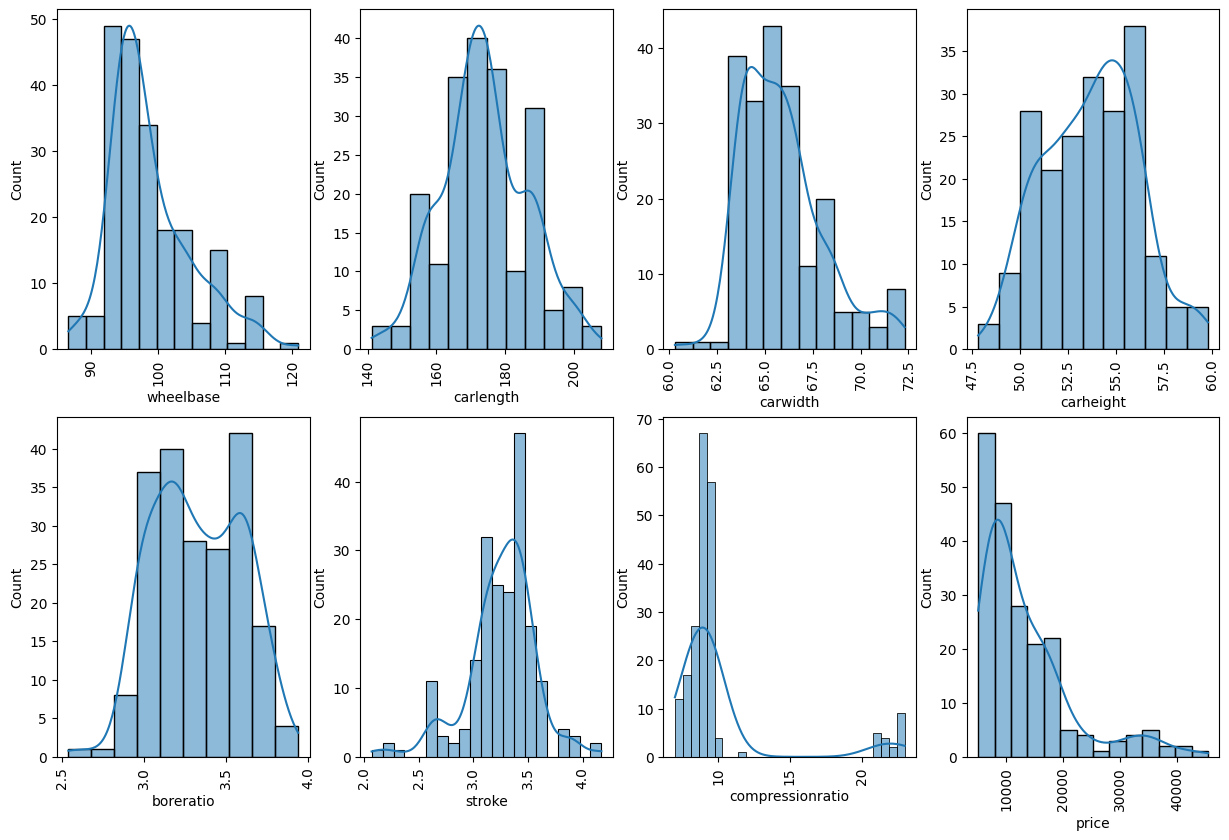

In [ ]:
plt.figure(figsize=(15,15))
for i,col in enumerate(df_fl.columns):
  plt.subplot(3,4,i+1)
  sns.histplot(data=df_fl,x=col,kde=True)
  plt.xticks(rotation=90)
plt.show()

In [ ]:
df_fl.skew().sort_values(ascending=False)

,0
compressionratio,2.610862
price,1.777678
wheelbase,1.050214
carwidth,0.904003
carlength,0.155954
carheight,0.063123
boreratio,0.020156
stroke,-0.689705


In [ ]:
df_fl['compressionratio']=np.log1p(df_fl['compressionratio'])
df_fl['wheelbase']=np.log(df_fl['wheelbase'])
df_fl['price']=np.log(df_fl['price'])

In [ ]:
df_fl.skew().sort_values(ascending=False)

,0
compressionratio,2.379056
carwidth,0.904003
wheelbase,0.883387
price,0.672889
carlength,0.155954
carheight,0.063123
boreratio,0.020156
stroke,-0.689705


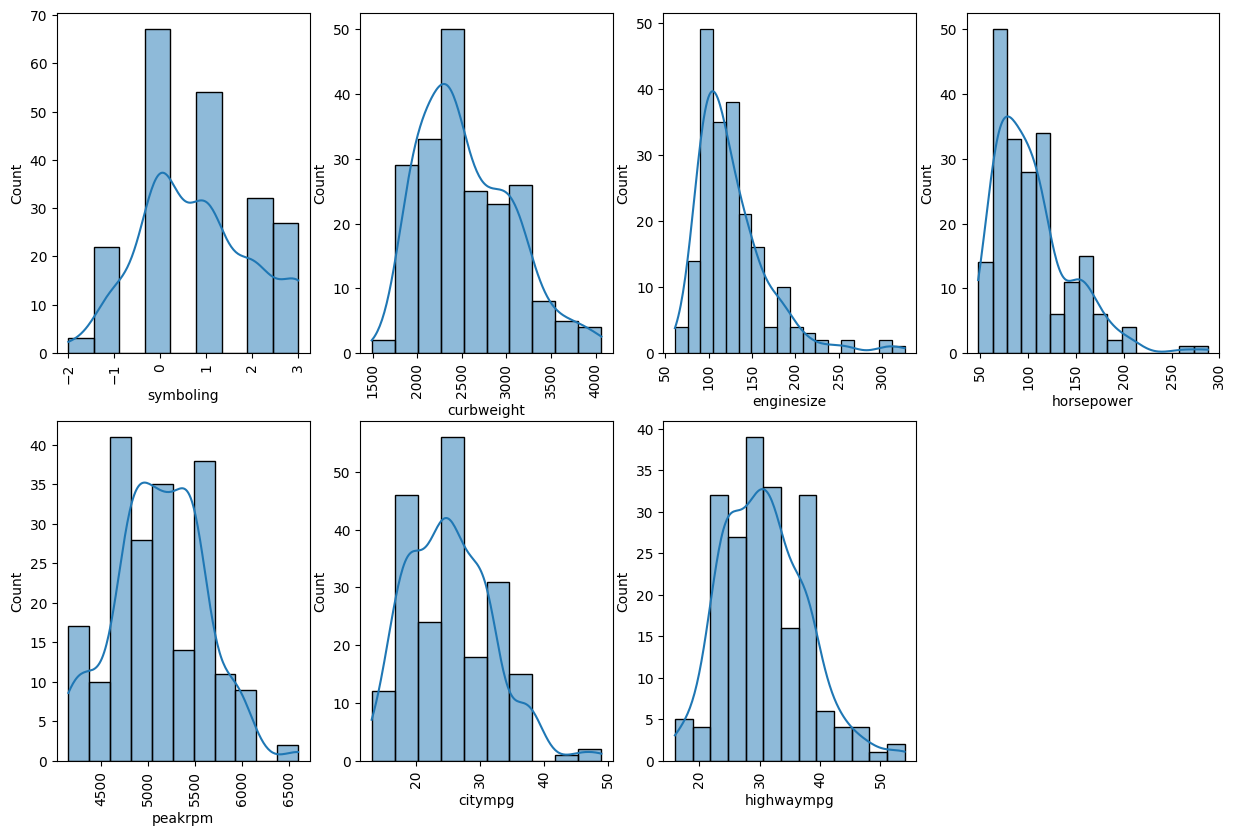

In [ ]:
plt.figure(figsize=(15,15))
for i,col in enumerate(df_int.columns):
  plt.subplot(3,4,i+1)
  sns.histplot(data=df_int,x=col,kde=True)
  plt.xticks(rotation=90)
plt.show()

In [ ]:
df_int.skew().sort_values(ascending=False)

,0
enginesize,1.947655
horsepower,1.405310
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997
symboling,0.211072
peakrpm,0.075159


In [ ]:
df_int['enginesize']=np.log(df_int['enginesize'])
df_int['horsepower']=np.log(df_int['horsepower'])

In [ ]:
df_int.skew().sort_values(ascending=False)

,0
enginesize,0.857828
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997
horsepower,0.482838
symboling,0.211072
peakrpm,0.075159


In [ ]:
df_num=pd.concat([df_fl,df_int],axis=1)

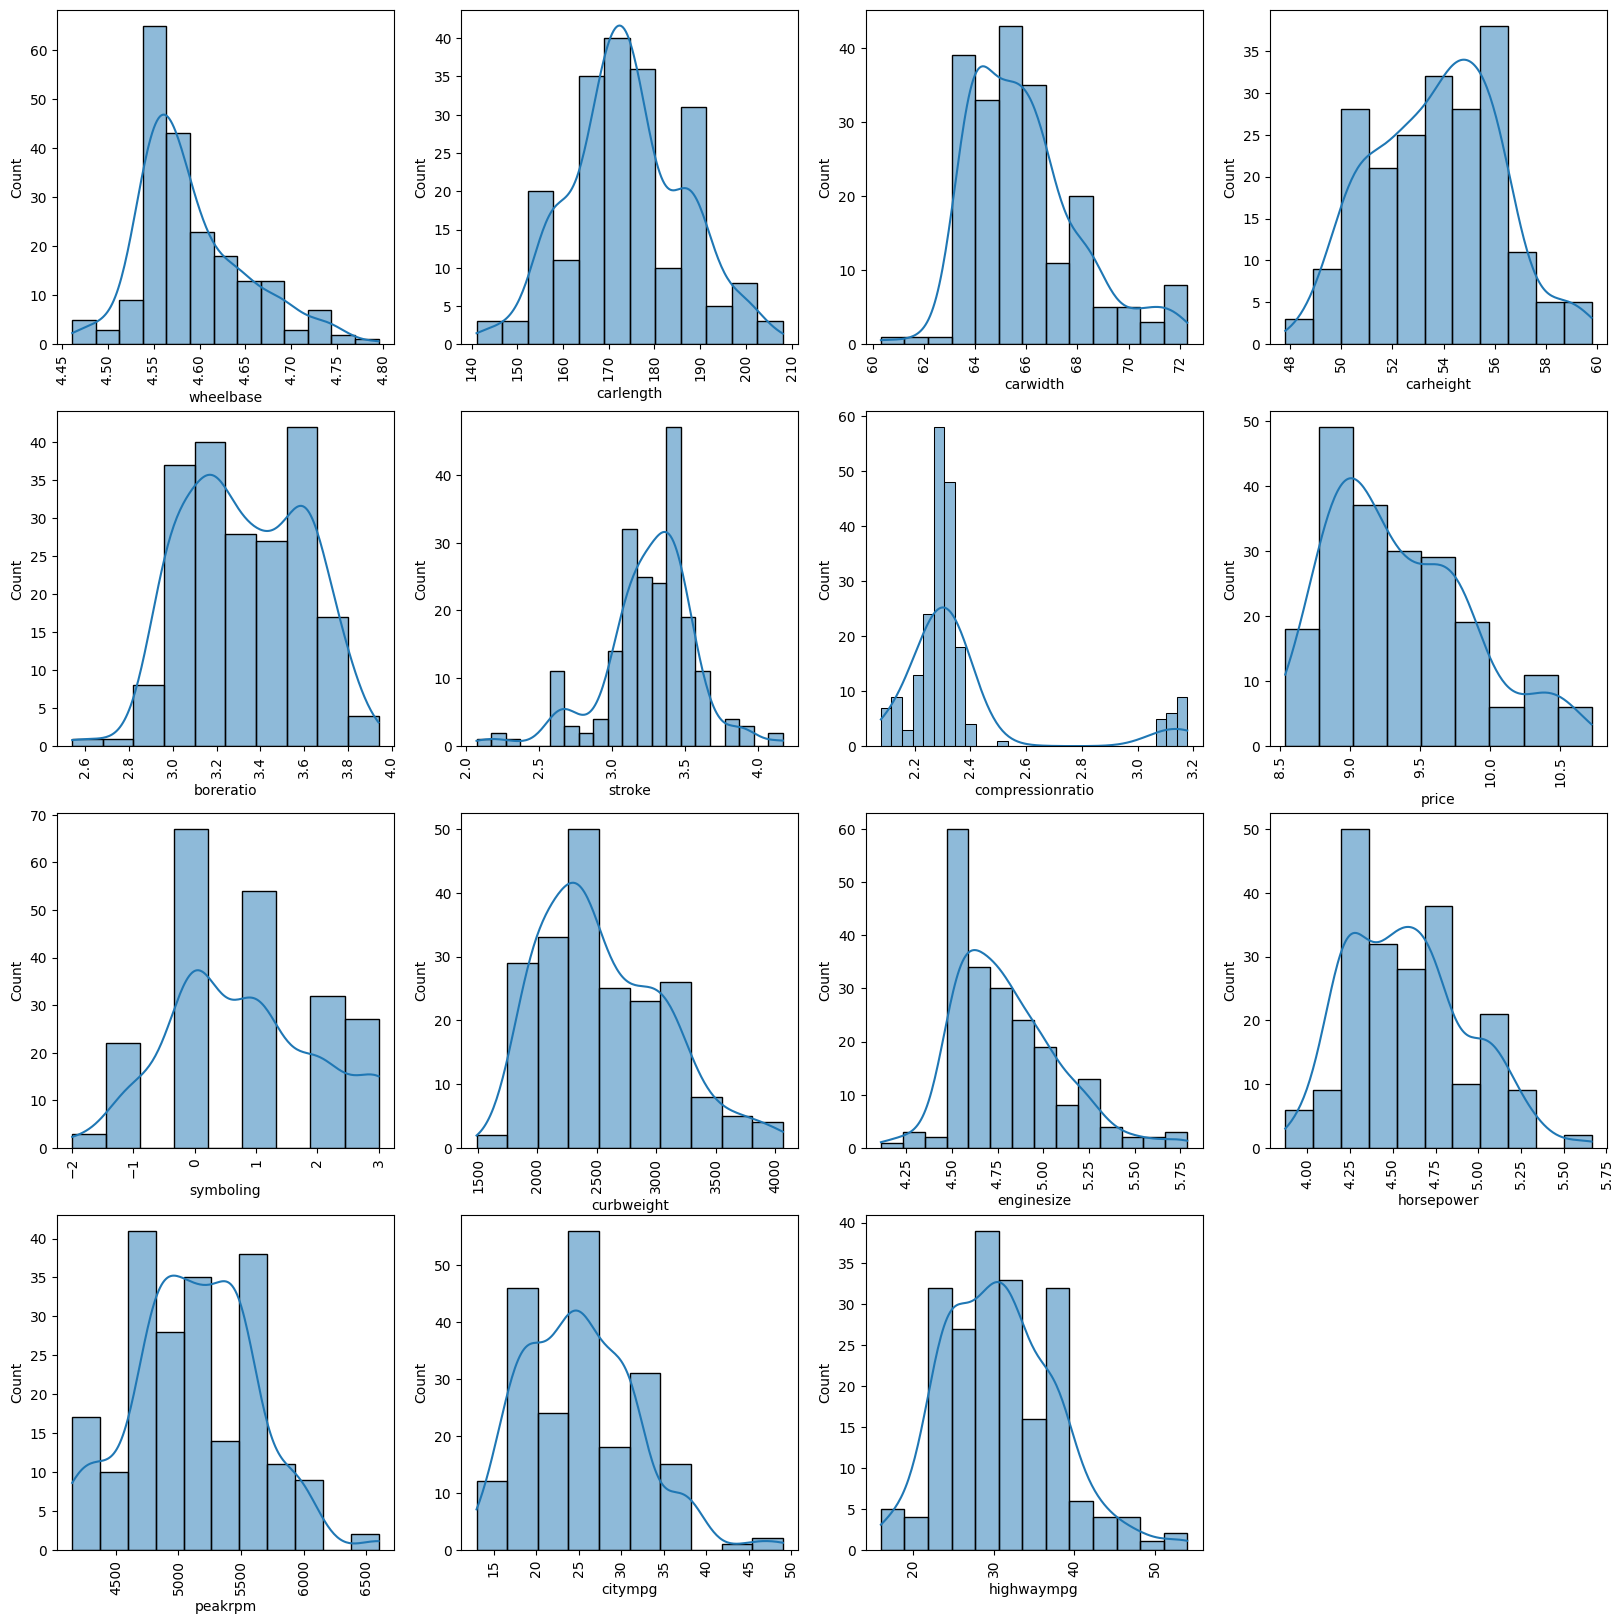

In [ ]:
plt.figure(figsize=(20,20))
for i, col in enumerate(df_num.columns):
  plt.subplot(4, 4, i + 1)
  sns.histplot(data=df_num, x=col, kde=True)
  plt.xticks(rotation=90)
plt.show()


Correlation

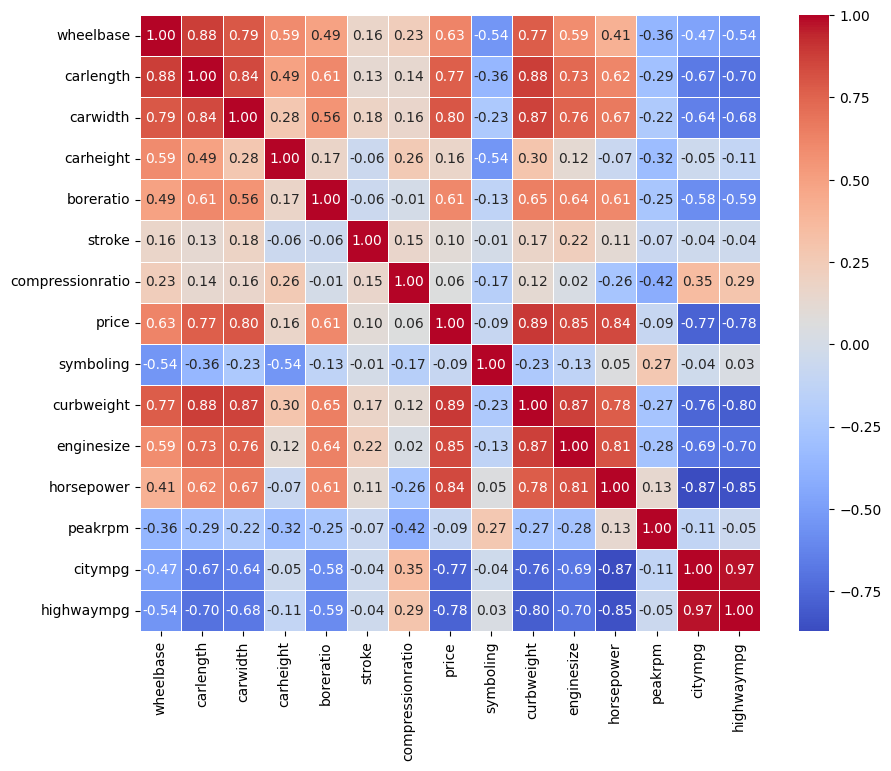

In [ ]:
plt.figure(figsize=(10,8))
sns.heatmap(df_num.corr(),annot=True,cmap='coolwarm',linewidths=0.5,fmt='.2f')
plt.show()

Outlier Removal

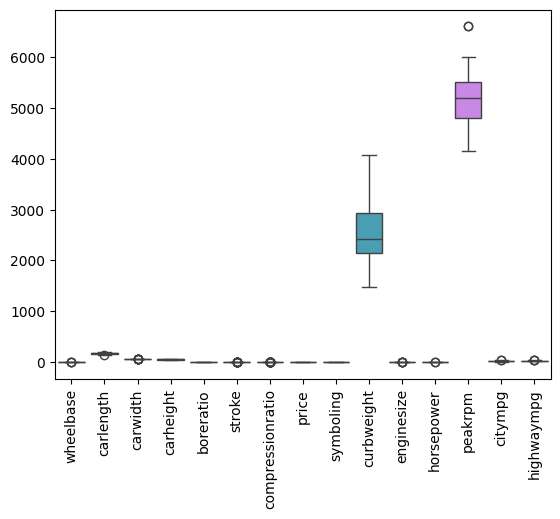

In [ ]:
sns.boxplot(data=df_num)
plt.xticks(rotation=90)
plt.show()

In [ ]:
Q1 = df_num.quantile(0.25)
Q3 = df_num.quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
median_value = df_num.median()

df_IQR_re = df_num.mask((df_num < lower_limit) | (df_num > upper_limit), median_value,axis=1)


In [ ]:
df_IQR_re.isnull().sum()

,0
wheelbase,0
carlength,0
carwidth,0
carheight,0
boreratio,0
stroke,0
compressionratio,0
price,0
symboling,0
curbweight,0


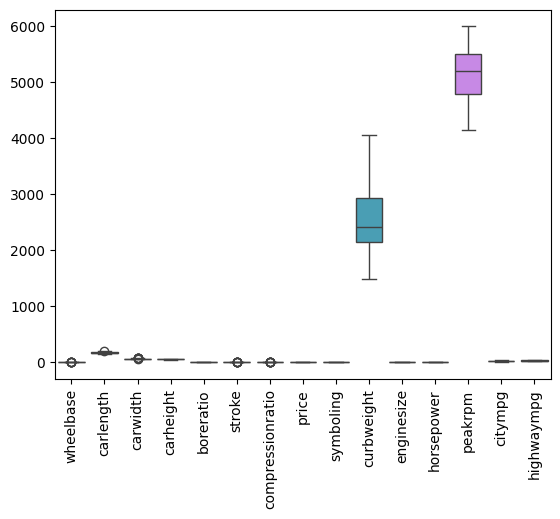

In [ ]:
sns.boxplot(data=df_IQR_re)
plt.xticks(rotation=90)
plt.show()

Train_Test_Split

In [ ]:
df_final=pd.concat([df_IQR_re,df_obj],axis=1)

In [ ]:
df_final.shape

(205, 24)

In [ ]:
X=df_final.drop('price',axis=1)
y=df_final['price']

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
X_tr_int=X_train.select_dtypes(exclude='object')
X_tr_obj=X_train.select_dtypes(include='object')

In [ ]:
X_ts_int=X_test.select_dtypes(exclude='object')
X_ts_obj=X_test.select_dtypes(include='object')

Best K Features

In [ ]:
selector=SelectKBest(f_regression,k=8)
X_tr_sl=selector.fit_transform(X_tr_int,y_train)
X_s=pd.DataFrame(X,columns=X_tr_int.columns[selector.get_support()])
X_ts_sl=selector.transform(X_ts_int)
X_ts_s=pd.DataFrame(X_ts_sl,columns=X_tr_int.columns[selector.get_support()])


Standardization

In [ ]:
scale=StandardScaler()
X_tr_sc=scale.fit_transform(X_tr_sl)
X_tr_sc=pd.DataFrame(X_tr_sc,columns=X_s.columns)
X_ts_sc=scale.transform(X_ts_sl)
X_ts_sc=pd.DataFrame(X_ts_sc,columns=X_ts_s.columns)

In [ ]:
y_train=scale.fit_transform(y_train.values.reshape(-1,1))
y_test=scale.transform(y_test.values.reshape(-1,1))

Encoding

In [ ]:
od=OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1)
X_en=od.fit_transform(X_tr_obj)
X_en=pd.DataFrame(X_en,columns=X_tr_obj.columns)
X_ts_en=od.transform(X_ts_obj)
X_ts_en=pd.DataFrame(X_ts_en,columns=X_ts_obj.columns)


In [ ]:
X_train_final=pd.concat([X_tr_sc,X_en],axis=1)
X_test_final=pd.concat([X_ts_sc,X_ts_en],axis=1)


In [ ]:
X_test_final = X_test_final.reindex(columns=X_train_final.columns)

Model building,Training and evaluation

In [ ]:
models = {'Linear Regression': LinearRegression(),
          'Decision Tree': DecisionTreeRegressor(random_state=42),
          'Random Forest': RandomForestRegressor(random_state=42),
          'Gradient Boosting': GradientBoostingRegressor(random_state=42),
          'Support Vector Regression': SVR()}

In [ ]:
results = []
trained_models = {}

for name, model in models.items():
  model.fit(X_train_final, y_train)
  y_pred = model.predict(X_test_final)
  r2 = r2_score(y_test, y_pred)
  mse = mean_squared_error(y_test, y_pred)
  mae = mean_absolute_error(y_test, y_pred)
  results.append({
        'Model': name,
        'R2 Score': r2,
        'MSE': mse,
        'MAE': mae})


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_gb.py:672: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)  # TODO: Is this still required?
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [ ]:
evaluation_df = pd.DataFrame(results)
evaluation_df = evaluation_df.sort_values(by='R2 Score',ascending=False).reset_index(drop=True)

evaluation_df

,Model,R2 Score,MSE,MAE
0,Random Forest,0.935828,0.070237,0.217879
1,Gradient Boosting,0.914488,0.093594,0.255392
2,Linear Regression,0.871118,0.141064,0.289527
3,Support Vector Regression,0.830462,0.185563,0.325117
4,Decision Tree,0.812243,0.205503,0.294590


Cross validation and Hyperparameter tuning

In [ ]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [ ]:
models = {'Linear Regression': (LinearRegression(),{'fit_intercept': [True, False]}),
          'Decision Tree': (DecisionTreeRegressor(random_state=42),
           {
            'max_depth': [3, 5, 7, 10, None],
            'min_samples_split': [2, 5, 10, 20],
            'min_samples_leaf': [1, 2, 5, 10]}),
          'Random Forest': (RandomForestRegressor(random_state=42),
        {
            'n_estimators': [100, 200, 300],
            'max_depth': [5, 8, 10, 15, None],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 5]}),
          'Gradient Boosting': (GradientBoostingRegressor(random_state=42),
        {
            'n_estimators': [50, 100, 150, 200],
            'learning_rate': [0.01, 0.05, 0.1],
            'max_depth': [2, 3, 4, 5],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 5]}),
          'Support Vector Regression': (SVR(),
        {
            'C': [0.1, 1, 10, 100],
            'kernel': ['linear', 'rbf'],
            'gamma': ['scale', 'auto'],
            'epsilon': [0.01, 0.1, 0.2, 0.5]})
}

In [ ]:
tuned_models = {}

tuning_results = []

for name, (model, params) in models.items():

    print("\nTuning:", name)

    grid = GridSearchCV(
        estimator=model,
        param_grid=params,
        cv=5,
        scoring='r2',
        n_jobs=-1,
        verbose=1
    )
    grid.fit(X_train_final, y_train)

    tuned_models[name] = grid.best_estimator_


    tuning_results.append({
        'Model': name,
        'Best Parameters': grid.best_params_,
        'Best CV R2 Score': grid.best_score_
    })

    print("Best Parameters:", grid.best_params_)
    print("Best CV R2 Score:", round(grid.best_score_, 4))


Tuning: Linear Regression
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Best Parameters: {'fit_intercept': True}
Best CV R2 Score: 0.839

Tuning: Decision Tree
Fitting 5 folds for each of 80 candidates, totalling 400 fits
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 5}
Best CV R2 Score: 0.7856

Tuning: Random Forest
Fitting 5 folds for each of 135 candidates, totalling 675 fits


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Best Parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Best CV R2 Score: 0.8804

Tuning: Gradient Boosting
Fitting 5 folds for each of 432 candidates, totalling 2160 fits


/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_gb.py:672: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)  # TODO: Is this still required?


Best Parameters: {'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 200}
Best CV R2 Score: 0.8978

Tuning: Support Vector Regression
Fitting 5 folds for each of 64 candidates, totalling 320 fits
Best Parameters: {'C': 10, 'epsilon': 0.01, 'gamma': 'auto', 'kernel': 'rbf'}
Best CV R2 Score: 0.8559


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [ ]:
tuning_df = pd.DataFrame(tuning_results)

tuning_df

,Model,Best Parameters,Best CV R2 Score
0,Linear Regression,{'fit_intercept': True},0.838972
1,Decision Tree,"{'max_depth': 5, 'min_samples_leaf': 2, 'min_s...",0.785643
2,Random Forest,"{'max_depth': 10, 'min_samples_leaf': 1, 'min_...",0.880422
3,Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 2, 'min_sa...",0.897801
4,Support Vector Regression,"{'C': 10, 'epsilon': 0.01, 'gamma': 'auto', 'k...",0.855938


In [ ]:
tuned_evaluation = []

for name, model in tuned_models.items():
   y_pred = model.predict(X_test_final)
   r2 = r2_score(y_test, y_pred)
   mse = mean_squared_error(y_test, y_pred)
   mae = mean_absolute_error(y_test, y_pred)
   tuned_evaluation.append({
        'Model': name,
        'R2 Score': round(r2, 4),
        'MSE': round(mse, 4),
        'MAE': round(mae, 4)
    })

tuned_evaluation_df = pd.DataFrame(tuned_evaluation)

tuned_evaluation_df.sort_values(
    by='R2 Score',
    ascending=False
).reset_index(drop=True)

,Model,R2 Score,MSE,MAE
0,Random Forest,0.9365,0.0696,0.2049
1,Gradient Boosting,0.9072,0.1016,0.2555
2,Linear Regression,0.8711,0.1411,0.2895
3,Support Vector Regression,0.8425,0.1724,0.2947
4,Decision Tree,0.8127,0.2050,0.3130


Random forest is the best model for prediction,Because it shows the highest value for r2 and least value for error.

In [ ]:
best_model = tuned_models['Random Forest']

print("Best Model: Random Forest")

Best Model: Random Forest


In [ ]:
import joblib

joblib.dump(best_model, 'best_random_forest_model.pkl')

print("Random Forest model saved successfully!")

Random Forest model saved successfully!
